# code_182 · Outcome semantics choose the likelihood and the decision

**Book:** section 34.5. Restart and run all cells. All imports, helpers and generated inputs are internal. Ordinary execution requires no files, network, credentials or GPU. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_34_GUIDE.md), [execution evidence](../CHAPTER_34_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_182).

Reference runtime: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, Torch 2.14.1 CPU. Allow two minutes to run and 45–90 minutes to interpret. Original small implementations expose actual updates and controls; they are not benchmark reproductions or field causal conclusions. Target semantics, censoring or exposure, information roles and independent assessment are explicit. Generated records do not establish field performance or intervention validity. Original scoped mechanisms are identified separately from native library models.


In [1]:
import platform,time,json,copy,hashlib,itertools
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn,threadpoolctl
from IPython.display import display
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
import torch
from torch import nn
START=time.perf_counter();SEED=7582;rng=np.random.default_rng(SEED)
torch.set_num_threads(1);torch.set_default_dtype(torch.float64);torch.manual_seed(SEED);torch.use_deterministic_algorithms(True)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__,'torch':torch.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0', 'torch': '2.14.1'}
CPU: Darwin arm64 seed: 7582


<a id="ordered-grades-are-not-distances"></a>
 ## Fit an ordered-threshold likelihood
 Source 1,000 and final 600 independent assets have two visible features and a latent logistic-noise severity. Thresholds−0.8,0.7 and 1.6 produce four ordered grades. Native statsmodels OrderedModel fits a proportional-odds logistic likelihood with no separate intercept; the thresholds carry location. Compare a nominal multinomial logistic model and a rounded/clipped ridge grade regressor. Grade accuracy and absolute step error answer different questions. Only the two probabilistic models get a log score; a rounded integer is not a supplied class distribution. Equal adjacent grade-step costs are declared for this exercise and are not physical damage distances. All settings are fixed before the final role.


,model,accuracy,absolute_grade_step_error,negative_log_probability
0,Ordinal,0.505000,0.635000,1.099656
1,Nominal,0.498333,0.636667,1.099639
2,Rounded ridge,0.451667,0.608333,NaN


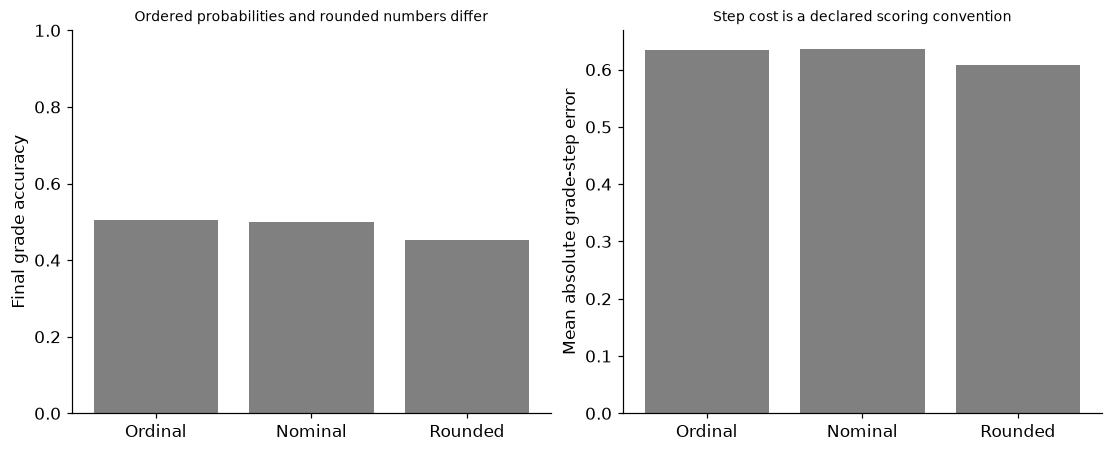

In [2]:
import statsmodels
from statsmodels.miscmodels.ordinal_model import OrderedModel
from sklearn.linear_model import LogisticRegression,Ridge,PoissonRegressor
from sklearn.metrics import log_loss,mean_pinball_loss
VERSIONS['statsmodels']=statsmodels.__version__
def ordinal_data(n,gr):
    x=gr.uniform(-1,1,(n,2));latent=1.3*x[:,0]-.7*x[:,1]+gr.logistic(scale=.6,size=n);return x,np.digitize(latent,[-.8,.7,1.6])
OX,OY=ordinal_data(1000,rng);TX,TY=ordinal_data(600,rng);ordinal=OrderedModel(OY,OX,distr='logit').fit(method='bfgs',disp=False,maxiter=300);op=ordinal.model.predict(ordinal.params,exog=TX);nominal=LogisticRegression(max_iter=500).fit(OX,OY);npred=nominal.predict_proba(TX);ridge=Ridge(alpha=1.).fit(OX,OY);rounded=np.clip(np.rint(ridge.predict(TX)),0,3).astype(int);grade_rows=[]
for name,pred,prob in [('Ordinal',np.argmax(op,axis=1),op),('Nominal',np.argmax(npred,axis=1),npred),('Rounded ridge',rounded,None)]:grade_rows.append({'model':name,'accuracy':float(np.mean(pred==TY)),'absolute_grade_step_error':float(np.mean(np.abs(pred-TY))),'negative_log_probability':None if prob is None else float(log_loss(TY,prob,labels=[0,1,2,3]))})
thresholds=ordinal.model.transform_threshold_params(ordinal.params)[1:-1];assert np.all(np.diff(thresholds)>0) and ordinal.mle_retvals['converged'];np.testing.assert_allclose(op.sum(1),1,atol=1e-10)
RESULTS.update(ordinal_source_assets=1000,ordinal_final_assets=600,ordinal_optimizer_converged=bool(ordinal.mle_retvals['converged']),fitted_ordered_thresholds=thresholds.tolist(),final_grade_metrics=grade_rows)
display(pd.DataFrame(grade_rows));fig,axes=plt.subplots(1,2,figsize=(10,4));axes[0].bar(range(3),[r['accuracy'] for r in grade_rows],color='.5');axes[0].set(xticks=range(3),xticklabels=['Ordinal','Nominal','Rounded'],ylim=(0,1),ylabel='Final grade accuracy',title='Ordered probabilities and rounded numbers differ');axes[1].bar(range(3),[r['absolute_grade_step_error'] for r in grade_rows],color='.5');axes[1].set(xticks=range(3),xticklabels=['Ordinal','Nominal','Rounded'],ylabel='Mean absolute grade-step error',title='Step cost is a declared scoring convention');plt.show()


<a id="overdispersed-count-likelihoods"></a>
 ## Separate a count intensity from extra zeros and overdispersion
 Independently generate 1,200 source/300 calibration/300 threshold-selection/600 final repair-count records. Within a fixed observation window, susceptible counts follow a negative-binomial mean exp(0.5+0.8 x 0) and dispersion 0.9. A distinct structural-zero probability logistic(0.8−x 1)mixes into those counts. The generated state is hidden from all fitting and assessment. A Poisson regressor assumes equal conditional variance and mean. Original maximum-likelihood NB and ZINB implementations use the NB 2 variance μ+αμ², stable log-gamma/log-add-exp calculations and actual autodifferentiated BFGS gradients. ZINB uses separate linear predictors for count mean and extra-zero probability. Two fixed initializations are compared only by source likelihood; the final role never selects parameters. Assess full count log score, zero probability and probability of at least five repairs. Extra zeros in an observed table alone do not identify an individual structural-zero state or prove this mixture family correct.


,model,negative_log_probability,predicted_zero_fraction,observed_zero_fraction,predicted_at_least5_fraction,observed_at_least5_fraction,count_mean_squared_error
0,Poisson,1.132344,0.617904,0.823333,0.002397,0.028333,2.139613
1,NB,0.773714,0.802694,0.823333,0.029566,0.028333,2.148372
2,ZINB,0.750682,0.805906,0.823333,0.032819,0.028333,2.141752


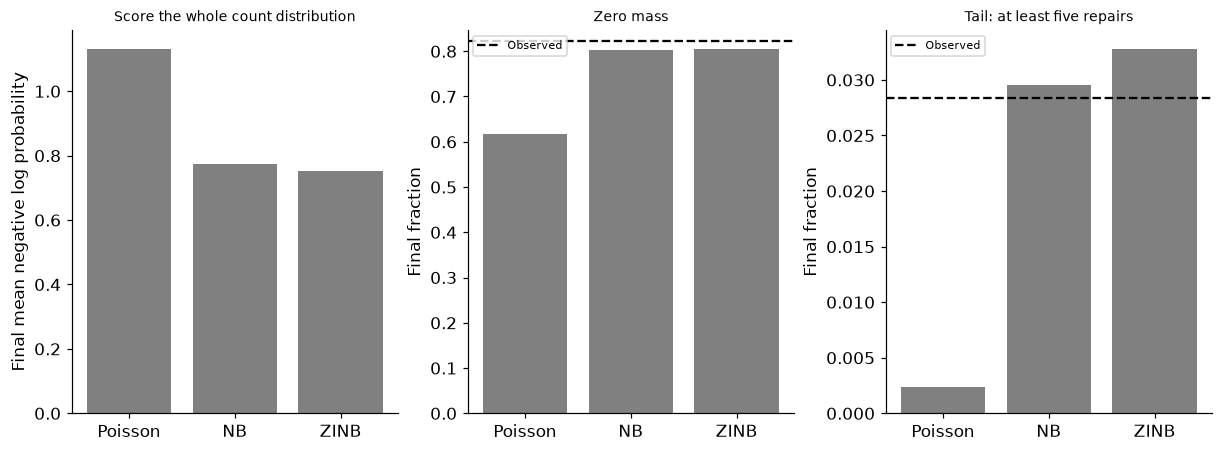

In [3]:
from scipy.optimize import minimize
from scipy.stats import poisson,nbinom
from scipy.special import expit,logit
def count_data(n,gr):
    x=gr.uniform(-1,1,(n,2));mu=np.exp(.5+.8*x[:,0]);pi=expit(.8-x[:,1]);count=gr.negative_binomial(1/.9,(1/.9)/(1/.9+mu));count=np.where(gr.random(n)<pi,0,count);return x,count
CX,CY=count_data(1200,rng);KX,KY=count_data(300,rng);VX,VY=count_data(300,rng);EX,EY=count_data(600,rng);design=np.c_[np.ones(len(CX)),CX];XT=torch.tensor(design);YT=torch.tensor(CY,dtype=torch.float64);pois=PoissonRegressor(alpha=0,max_iter=500,tol=1e-9).fit(CX,CY)
def count_objective(theta,zero):
    z=torch.tensor(theta,requires_grad=True);mu=torch.exp(XT@z[:3]);alpha=nn.functional.softplus(z[3])+1e-4;r=1/alpha;nb=torch.lgamma(YT+r)-torch.lgamma(r)-torch.lgamma(YT+1)+r*(torch.log(r)-torch.log(r+mu))+YT*(torch.log(mu)-torch.log(r+mu))
    if zero:
        eta=XT@z[4:7];lp=nn.functional.logsigmoid(eta);lq=nn.functional.logsigmoid(-eta);ll=torch.where(YT==0,torch.logaddexp(lp,lq+nb),lq+nb)
    else:ll=nb
    loss=-ll.mean();loss.backward();return float(loss.detach()),z.grad.numpy()
nb_start=np.r_[pois.intercept_,pois.coef_,0.];nb_fit=minimize(count_objective,nb_start,args=(False,),jac=True,method='BFGS',options={'gtol':1e-7,'maxiter':400});starts=[np.r_[nb_fit.x[:3]+np.array([.3,0,0]),nb_fit.x[3],-1.,0.,0.],np.r_[nb_fit.x[:3]+np.array([.7,0,0]),nb_fit.x[3],0.,0.,-.5]];zi_fits=[minimize(count_objective,z,args=(True,),jac=True,method='BFGS',options={'gtol':1e-7,'maxiter':400}) for z in starts];zi_fit=min(zi_fits,key=lambda f:f.fun)
def distribution(name,x,y):
    if name=='Poisson':mu=pois.predict(x);return poisson.logpmf(y,mu),np.exp(-mu),poisson.sf(4,mu),mu
    z=nb_fit.x if name=='NB' else zi_fit.x;D=np.c_[np.ones(len(x)),x];mu=np.exp(D@z[:3]);alpha=np.logaddexp(0,z[3])+1e-4;r=1/alpha;p=r/(r+mu);pi=np.zeros(len(x)) if name=='NB' else expit(D@z[4:7]);lognb=nbinom.logpmf(y,r,p);ll=lognb if name=='NB' else np.where(y==0,np.logaddexp(np.log(pi),np.log1p(-pi)+lognb),np.log1p(-pi)+lognb);return ll,pi+(1-pi)*nbinom.pmf(0,r,p),(1-pi)*nbinom.sf(4,r,p),(1-pi)*mu
count_rows=[]
for name in ['Poisson','NB','ZINB']:
    ll,p0,tail,mean=distribution(name,EX,EY);count_rows.append({'model':name,'negative_log_probability':float(-ll.mean()),'predicted_zero_fraction':float(p0.mean()),'observed_zero_fraction':float(np.mean(EY==0)),'predicted_at_least5_fraction':float(tail.mean()),'observed_at_least5_fraction':float(np.mean(EY>=5)),'count_mean_squared_error':float(np.mean((mean-EY)**2))})
assert np.linalg.norm(nb_fit.jac)<1e-4 and np.linalg.norm(zi_fit.jac)<1e-4 and np.isfinite([r['negative_log_probability'] for r in count_rows]).all();assert CY.min()>=0 and np.issubdtype(CY.dtype,np.integer)
RESULTS.update(count_role_sizes={'source':1200,'calibration':300,'threshold_selection':300,'final':600},NB_optimizer={'success':bool(nb_fit.success),'gradient_norm':float(np.linalg.norm(nb_fit.jac)),'dispersion':float(np.logaddexp(0,nb_fit.x[3])+1e-4)},ZINB_optimizer={'success':bool(zi_fit.success),'gradient_norm':float(np.linalg.norm(zi_fit.jac)),'dispersion':float(np.logaddexp(0,zi_fit.x[3])+1e-4),'source_start_losses':[float(f.fun) for f in zi_fits]},final_count_metrics=count_rows,structural_zero_labels_observed=False)
display(pd.DataFrame(count_rows));fig,axes=plt.subplots(1,3,figsize=(11,4));names=['Poisson','NB','ZINB'];axes[0].bar(range(3),[r['negative_log_probability'] for r in count_rows],color='.5');axes[0].set(ylabel='Final mean negative log probability',title='Score the whole count distribution')
for ax,key,observed,title in [(axes[1],'predicted_zero_fraction','observed_zero_fraction','Zero mass'),(axes[2],'predicted_at_least5_fraction','observed_at_least5_fraction','Tail: at least five repairs')]:
    ax.bar(range(3),[r[key] for r in count_rows],color='.5');ax.axhline(count_rows[0][observed],color='black',linestyle='--',label='Observed');ax.set(ylabel='Final fraction',title=title);ax.legend(fontsize=7)
for ax in axes:ax.set_xticks(range(3),names)
plt.show()


<a id="rare-costs-and-quantile-bands"></a>
 ## Calibrate a rare threshold event and score a separate continuous distribution
 The event of five or more repairs has false-negative cost 10 and false-positive cost 1. Fit a sigmoid calibration map to raw ZINB tail probabilities using only the 300 calibration records. Select one threshold minimizing empirical cost on a separate 300 selection records, preferring the higher threshold on ties. Compare this fixed selection with 0.5 and the calibrated-probability Bayes threshold 1/11 on the 600 final records. Count prevalence, misses and false alarms; a low cost on one finite sample is not a field guarantee. No final metric selects calibration or a threshold.

 Separately generate 1,000 source/500 final continuous repair burdens with heteroscedastic noise. Native histogram gradient boosting fits 0.1/0.5/0.9 conditional quantiles with fixed 120 iterations, depth 3 and learning rate 0.08. Report pinball loss for each quantile, crossing fraction, central 80%interval coverage and width. Sorting three predictions enforces order but does not establish coverage. The plotted band uses a fixed second feature of zero; only final points close to that slice are overlaid. Coverage and scores use all 500 final records, not just the displayed slice.


,threshold_rule,threshold,positive_count,missed,false_alarms,recall,mean_cost
0,Half,0.500000,17,17,0,0.000000,0.283333
1,Bayes,0.090909,17,17,0,0.000000,0.283333
2,Selected,0.050000,17,15,10,0.117647,0.266667


,state,pinball_losses,central80_coverage,mean_interval_width
0,Raw,"[0.11696255937319769, 0.2558225593363592, 0.11...",0.728,1.414865
1,Sorted,"[0.11696255937319769, 0.255729783721167, 0.119...",0.728,1.415051


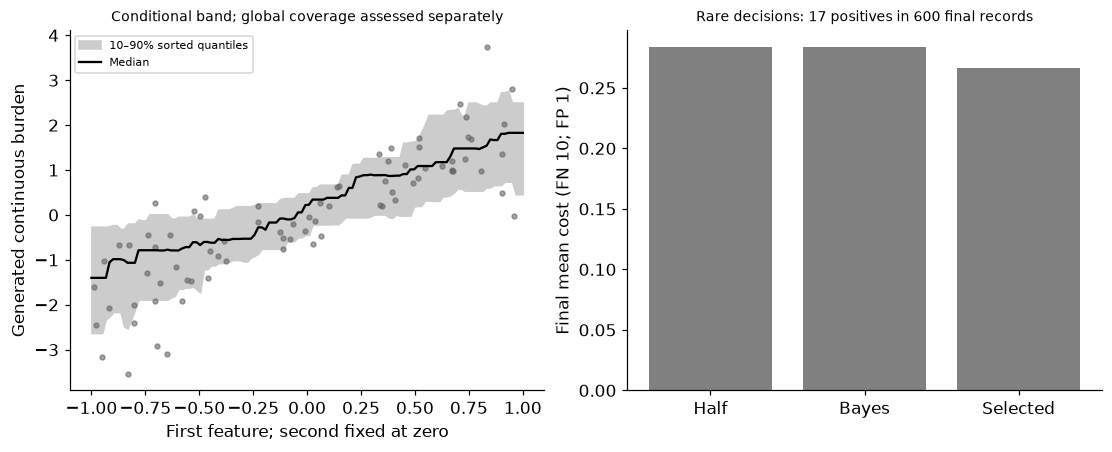

In [4]:
raw_cal=distribution('ZINB',KX,KY)[2];cal=LogisticRegression(C=1.,max_iter=500).fit(logit(np.clip(raw_cal,1e-6,1-1e-6))[:,None],(KY>=5).astype(int))
def calibrated(x):return cal.predict_proba(logit(np.clip(distribution('ZINB',x,np.zeros(len(x),int))[2],1e-6,1-1e-6))[:,None])[:,1]
vp=calibrated(VX);vy=VY>=5;grid=np.unique(np.r_[np.linspace(0,1,101),.5,1/11]);costs=np.array([np.mean(10*(vy&(vp<t))+(~vy&(vp>=t))) for t in grid]);selected=float(grid[np.flatnonzero(costs==costs.min())[-1]]);ep=calibrated(EX);ey=EY>=5;cost_rows=[]
for name,t in [('Half',.5),('Bayes',1/11),('Selected',selected)]:
    decision=ep>=t;fn=int(np.sum(ey&~decision));fp=int(np.sum(~ey&decision));tp=int(np.sum(ey&decision));cost_rows.append({'threshold_rule':name,'threshold':t,'positive_count':int(ey.sum()),'missed':fn,'false_alarms':fp,'recall':float(tp/max(ey.sum(),1)),'mean_cost':float((10*fn+fp)/len(ey))})
from sklearn.ensemble import HistGradientBoostingRegressor
def burden(n,gr):
    x=gr.uniform(-1,1,(n,2));y=2*x[:,0]+np.sin(2*x[:,1])+(.3+.6*np.abs(x[:,0]))*gr.normal(size=n);return x,y
QX,QY=burden(1000,rng);QF,QV=burden(500,rng);qs=np.array([.1,.5,.9]);qmodels=[HistGradientBoostingRegressor(loss='quantile',quantile=float(q),max_iter=120,max_depth=3,learning_rate=.08,random_state=SEED).fit(QX,QY) for q in qs];qp=np.column_stack([m.predict(QF) for m in qmodels]);ordered=np.sort(qp,axis=1);cross=float(np.mean(np.any(np.diff(qp,axis=1)<0,axis=1)));quantile_rows=[]
for state,pred in [('Raw',qp),('Sorted',ordered)]:quantile_rows.append({'state':state,'pinball_losses':[float(mean_pinball_loss(QV,pred[:,j],alpha=float(q))) for j,q in enumerate(qs)],'central80_coverage':float(np.mean((QV>=pred[:,0])&(QV<=pred[:,2]))),'mean_interval_width':float(np.mean(pred[:,2]-pred[:,0]))})
assert len(set(grid))==len(grid) and all(0<=r['recall']<=1 for r in cost_rows);assert np.all(np.diff(ordered,axis=1)>=0) and np.isfinite(qp).all();assert len(KY)==len(VY)==300 and len(EY)==600
RESULTS.update(rare_calibration_positives=int(np.sum(KY>=5)),rare_selection_positives=int(np.sum(VY>=5)),rare_final_positives=int(ey.sum()),false_negative_cost=10,false_positive_cost=1,selected_threshold=selected,final_threshold_metrics=cost_rows,final_tail_Brier_raw=float(np.mean((distribution('ZINB',EX,EY)[2]-ey)**2)),final_tail_Brier_calibrated=float(np.mean((ep-ey)**2)),quantile_source_size=1000,quantile_final_size=500,quantile_crossing_fraction=cross,final_quantile_metrics=quantile_rows,final_used_for_selection=False)
display(pd.DataFrame(cost_rows));display(pd.DataFrame(quantile_rows));fig,axes=plt.subplots(1,2,figsize=(10,4));line=np.linspace(-1,1,120);slice_x=np.c_[line,np.zeros(120)];band=np.sort(np.column_stack([m.predict(slice_x) for m in qmodels]),axis=1);near=np.abs(QF[:,1])<.15;axes[0].fill_between(line,band[:,0],band[:,2],color='.8',label='10–90% sorted quantiles');axes[0].plot(line,band[:,1],color='black',label='Median');axes[0].scatter(QF[near,0],QV[near],s=10,color='.4',alpha=.6);axes[0].set(xlabel='First feature; second fixed at zero',ylabel='Generated continuous burden',title='Conditional band; global coverage assessed separately');axes[0].legend(fontsize=7);axes[1].bar(range(3),[r['mean_cost'] for r in cost_rows],color='.5');axes[1].set(xticks=range(3),xticklabels=['Half','Bayes','Selected'],ylabel='Final mean cost (FN 10; FP 1)',title=f'Rare decisions: {int(ey.sum())} positives in 600 final records');plt.show()


In [5]:
summary={'example_id':'code_182','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['native proportional-odds ordered likelihood versus nominal and rounded controls', 'actual Poisson negative-binomial and zero-inflated negative-binomial fitting', 'separate source calibration threshold selection and final rare-event roles', 'native conditional quantile fitting with crossing coverage and pinball checks', 'distributional zero and tail assessment without latent-class certainty'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["native proportional-odds ordered likelihood versus nominal and rounded controls", "actual Poisson negative-binomial and zero-inflated negative-binomial fitting", "separate source calibration threshold selection and final rare-event roles", "native conditional quantile fitting with crossing coverage and pinball checks", "distributional zero and tail assessment without latent-class certainty"], "elapsed_seconds": 0.988, "example_id": "code_182", "hardware": "Darwin arm64 CPU", "results": {"NB_optimizer": {"dispersion": 5.969429117922576, "gradient_norm": 1.6328822334661536e-08, "success": true}, "ZINB_optimizer": {"dispersion": 0.7340572724020638, "gradient_norm": 1.9907519547322847e-08, "source_start_losses": [0.8252009734595714, 0.8252009734595368], "success": true}, "count_role_sizes": {"calibration": 300, "final": 600, "source": 1200, "threshold_selection": 300}, "false_negative_cost": 10, "false_positive_cost": 1, "final_count_metri